# $L(2,\chi_{-3})$: historical construction and new trajectory

The CMF examples sample every 10 depths through depth 3000.
Each example prints its final $\delta_N$; the figure at the end plots
$\delta_N$ against $N$, where
$$D_N=-\log_{10}\left|L(2,\chi_{-3})-\frac{p_N}{q_N}\right|,
\qquad \delta_N=\frac{D_N}{\log_{10}q_N}-1.$$
Here $p_N/q_N$ is reduced. Accuracy digits measure absolute approximation error.

Run the cells in order (Python 3.11+). The finite-depth $\delta_N$ values are
numerical estimates, not proved limiting exponents.

Here
$$L(2,\chi_{-3})=\sum_{k\ge0}\left(\frac1{(3k+1)^2}-\frac1{(3k+2)^2}\right)
=\frac2{\sqrt3}\operatorname{Im}\operatorname{Li}_2\bigl(e^{2\pi i/3}\bigr),$$
computed through the dilogarithm, which is much faster at this precision than
the Hurwitz zeta function.

In [1]:
# @title Install dependencies (run once per environment)
%pip -q install ramanujantools==0.0.8 sympy==1.14.0 matplotlib==3.11.2

## Setup

The example constructs a CMF, walks a trajectory with ramanujantools, reads
$p_N/q_N$ off the first column $(s_0,s_1,\ldots)$ of the walk, and computes
$\delta_N$. The walks and the approximants are exact.

In [1]:
import sys

import matplotlib.pyplot as plt
import sympy as sp
from flint import acb, arb, ctx
from ramanujantools.cmf.pfq import pFq

sys.set_int_max_str_digits(0)
with ctx.workdps(190_000):  # q_N reaches about 90,000 digits at depth 3000
    L2CHI3 = 2 / arb(3).sqrt() * acb.polylog(acb.exp_pi_i(acb(2) / 3), 2).imag
DEPTHS = list(range(10, 3001, 10))
x0, x1, x2, x3, y0, y1, y2 = sp.symbols("x0 x1 x2 x3 y0 y1 y2")
results = {}


def delta(approximant):
    """delta with |L(2, χ_-3) - p/q| = q^-(1 + delta), for the reduced fraction p/q."""
    p, q = int(approximant.p), int(approximant.q)
    with ctx.workprec(2 * q.bit_length() + 64):  # enough bits to resolve |L(2, χ_-3) - p/q|
        error = abs(L2CHI3 - arb(p) / q)
    return float((-1 - error.log() / arb(q).log()).mid())

## 1. Zagier (2009)

D. Zagier, *Integral solutions of Apéry-like recurrence equations*,
in *Groups and Symmetries*, CRM Proc. Lecture Notes **47** (2009), 349–366.
[Paper](https://people.mpim-bonn.mpg.de/zagier/files/tex/AperylikeRecEqs/fulltext.pdf).
Zagier's case C is the recurrence
$$(n+1)^2u_{n+1}=(10n^2+10n+3)u_n-9n^2u_{n-1}.$$
Its solution $a_n=\sum_k\binom nk^2\binom{2k}k={}_3F_2(-n,-n,\tfrac12;1,1;4)$
has $a_0=1$, and the solution $b_n$ with $b_0=0$, $b_1=1$ has
$[1,\ldots,n]^2b_n\in\mathbb Z$ and $b_n/a_n\to L(2,\chi_{-3})/2$
([Calegari–Dimitrov–Tang (2024), Lemma 11.1.4](https://arxiv.org/abs/2408.15403)).
The characteristic roots $9$ and $1$ and the denominators $[1,\ldots,n]^2$
give $\delta=\log9/(2+\log9)-1=-0.47651$.

**CMF:** ${}_3F_2(4)$ · **Start:** $(0,0,\tfrac12;1,1)$ · **Direction:** $(-1,-1,0;0,0)$.
Here we use the **direct** walk. Its first column is
$(s_0,s_1,s_2)=(a_N,0,-9b_N)$, so the extraction is
$$\frac{p_N}{q_N}=\frac{-2s_2}{9s_0}=\frac{2b_N}{a_N}.$$

In [2]:
cmf = pFq(3, 2, 4)
half = sp.Rational(1, 2)
start = {x0: 0, x1: 0, x2: half, y0: 1, y1: 1}
trajectory = {x0: -1, x1: -1, x2: 0, y0: 0, y1: 0}
walks = cmf.walk(trajectory, DEPTHS, start)
approximants = [-2 * W[2, 0] / (9 * W[0, 0]) for W in walks]
deltas = [delta(r) for r in approximants]
results["Zagier (2009)"] = (DEPTHS, deltas)
print(f"delta at depth 3000: {deltas[-1]:.9f}")

delta at depth 3000: -0.474521766


## 2. New ${}_4F_3(\tfrac14)$ trajectory

The experimental $L(2,\chi_{-3})$ trajectory of the paper (Appendix B and
the table of search results), with a numerical exponent near $-0.05909$.

**CMF:** ${}_4F_3(\tfrac14)$ · **Start:**
$(\tfrac12,\tfrac12,\tfrac12,\tfrac12;\tfrac32,\tfrac32,\tfrac32)$ ·
**Direction:** $(5,7,6,8;17,18,8)$. We use the inverse-transpose walk. With
$c_j=s_j/s_0$, the extraction is
$$\frac{p_N}{q_N}=\frac{-16c_1-8}{-54c_1-108c_2-72c_3-9}.$$
At the start this readout equals $\bigl(3\psi_1(\tfrac13)-\psi_1(\tfrac56)\bigr)/36
=L(2,\chi_{-3})$ (paper, Appendix B).

In [3]:
cmf = pFq(4, 3, sp.Rational(1, 4)).dual()  # inverse-transpose matrices
half = sp.Rational(1, 2)
start = {x0: half, x1: half, x2: half, x3: half, y0: 3 * half, y1: 3 * half, y2: 3 * half}
trajectory = {x0: 5, x1: 7, x2: 6, x3: 8, y0: 17, y1: 18, y2: 8}
walks = cmf.walk(trajectory, DEPTHS, start)
approximants = []
for W in walks:
    c1, c2, c3 = (W[j, 0] / W[0, 0] for j in (1, 2, 3))
    approximants.append((-16 * c1 - 8) / (-54 * c1 - 108 * c2 - 72 * c3 - 9))
deltas = [delta(r) for r in approximants]
results["New ${}_4F_3(1/4)$ trajectory"] = (DEPTHS, deltas)
print(f"delta at depth 3000: {deltas[-1]:.9f}")

delta at depth 3000: -0.059672070


## Figure

$\delta_N$ against the walk depth $N$.

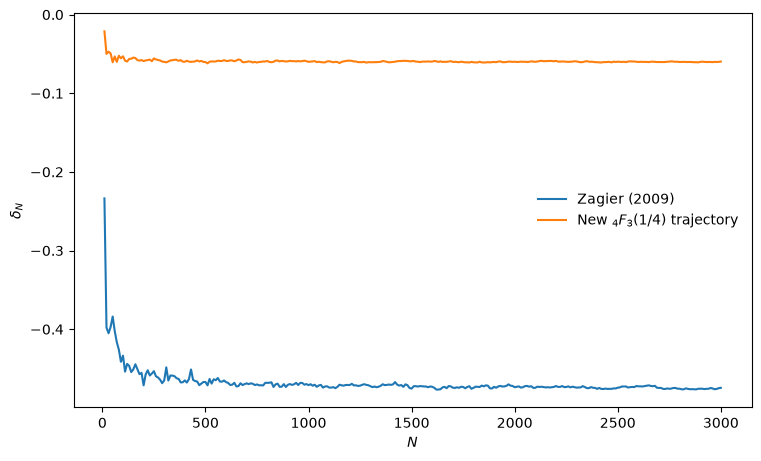

In [4]:
fig, ax = plt.subplots(figsize=(7.5, 4.5), constrained_layout=True)
for name, (depths, values) in results.items():
    ax.plot(depths, values, label=name)
ax.set(xlabel="$N$", ylabel=r"$\delta_N$")
ax.legend(frameon=False)
plt.show()

## Overview

| Construction | Exponent | Notebook coverage |
|:--|--:|:--|
| [Zagier (2009)](https://people.mpim-bonn.mpg.de/zagier/files/tex/AperylikeRecEqs/fulltext.pdf) | $\delta=-0.47651$ | CMF above |
| This work | $\delta\approx-0.05909$ | CMF above |

Zagier's exponent is $\delta=c-1$ with $c=\log9/(2+\log9)=0.52349\ldots$;
see [Calegari–Dimitrov–Tang (2024), §11.1](https://arxiv.org/abs/2408.15403),
who prove that $1,\zeta(2),L(2,\chi_{-3})$ are linearly independent over
$\mathbb Q$. Their sequel gives $\mu(L(2,\chi_{-3}))\le24781$
([Theorem 5.1](https://arxiv.org/abs/2510.04156)).
Neither exponent
reaches the threshold $\delta=0$.